1317_Alvalade


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


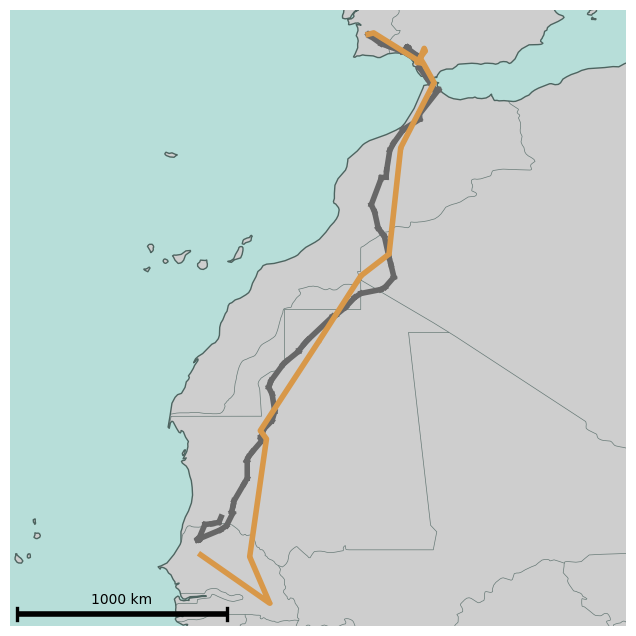

In [ ]:
import pandas as pd
import numpy as np
import math

import torch
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pyproj import Transformer

import movebench.paths as paths

MAP_RIVERS_LAKES_COLOR = "#538a81"
MAP_OCEAN_COLOR = "#b7ded9"
MAP_LAND_COLOR = "#CECECE"
MAP_COASTLINE_COLOR = "#4d6460"
MAP_OBSERVED_COLOR = "#676767"
MAP_PREDICTED_COLOR = "#d89849"



def haversine(lat1, lon1, lat2, lon2):
    # Radius of Earth in kilometers. Use 3956 for miles
    R = 6371.0

    # Convert degrees to radians
    phi1 = math.radians(lat1)
    phi2 = math.radians(lat2)
    delta_phi = math.radians(lat2 - lat1)
    delta_lambda = math.radians(lon2 - lon1)

    # Haversine formula
    a = math.sin(delta_phi / 2)**2 + \
        math.cos(phi1) * math.cos(phi2) * \
        math.sin(delta_lambda / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))

    return R * c  * 1000

def add_scalebar(ax, length_km=100, location=(0.08, 0.05), linewidth=4):
    """
    Add an approximate scale bar to a Cartopy GeoAxes in PlateCarree coordinates.

    Parameters
    ----------
    ax : cartopy.mpl.geoaxes.GeoAxes
        The map axes.
    length_km : float
        Scale bar length in kilometers.
    location : tuple
        (x_frac, y_frac) position in axes/data extent fraction,
        e.g. (0.08, 0.05) is near bottom-left.
    linewidth : float
        Thickness of the scale bar line.
    """

    # Current extent in lon/lat
    lon_min, lon_max = ax.get_xlim()
    lat_min, lat_max = ax.get_ylim()

    # Position of the left end of the scale bar
    lon0 = lon_min + (lon_max - lon_min) * location[0]
    lat0 = lat_min + (lat_max - lat_min) * location[1]

    # Convert desired length (km) to degrees longitude at this latitude
    # Approx: 1 deg longitude = 111.32 km * cos(latitude)
    km_per_deg_lon = 111.32 * math.cos(math.radians(lat0))
    delta_lon = length_km / km_per_deg_lon

    lon1 = lon0 + delta_lon

    # Draw the scale bar
    ax.plot([lon0, lon1], [lat0, lat0],
            transform=ccrs.PlateCarree(),
            color="black", linewidth=linewidth, solid_capstyle="butt")

    # Optional end ticks
    tick_height = (lat_max - lat_min) * 0.01
    ax.plot([lon0, lon0], [lat0 - tick_height, lat0 + tick_height],
            transform=ccrs.PlateCarree(),
            color="black", linewidth=linewidth * 0.6)
    ax.plot([lon1, lon1], [lat0 - tick_height, lat0 + tick_height],
            transform=ccrs.PlateCarree(),
            color="black", linewidth=linewidth * 0.6)

    # Label
    ax.text((lon0 + lon1) / 2, lat0 + tick_height * 1.1,
            f"{length_km} km",
            transform=ccrs.PlateCarree(),
            ha="center", va="bottom",
            fontsize=10,
            )



study_id = "Accio_967b7813_raw_merged"
df = pd.read_csv(
    # paths.study_dir(study_id) / "trajectories.csv",
    f"../cleaned-v3-filtered/{study_id}.csv",
    # usecols=["individual-local-identifier", "timestamp", "location-long", "location-lat"],
    parse_dates=["timestamp"],
)

df = df[df.set == 'test_temporal']
individual_id = df["individual-local-identifier"].value_counts().idxmax()
# individual_id = df["individual-local-identifier"].unique()[0] #_counts().idxmax()
print(individual_id)

track = df[df["individual-local-identifier"] == individual_id].sort_values("timestamp")
track = track[track.step_length_m < track.step_length_m.quantile(0.99)]

### PREDS
track_12h = track.iloc[::12].copy()
pred_path = max(
    (
        p
        for p in (paths.repo_root() / "results" / "bench" / "runs").glob(
            f"study={study_id}__ts=12h__cov=all__method=issf_mlp__seed=0__k=*/predictions/test_temporal.pt"
        )
    ),
    key=lambda p: p.stat().st_mtime,
)
pred_payload = torch.load(pred_path, map_location="cpu")
pred_index = {
    int(point_id): i for i, point_id in enumerate(pred_payload["point_id_start"].tolist())
}
to_3857 = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
from_3857 = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)

# start at start point
pred_lon = [track.start_lon.values[0]]
pred_lat = [track.start_lat.values[0]]
g = torch.Generator().manual_seed(1)
h, w = pred_payload["scores"].shape[1:]
for row in track_12h.itertuples(index=False):
    idx = pred_index.get(int(row.point_id_start))
    if idx is None:
        continue
    pix = int(
        torch.multinomial(
            torch.softmax(pred_payload["scores"][idx].reshape(-1), dim=0),
            1,
            generator=g,
        ).item()
    )
    sample_row, sample_col = divmod(pix, w)
    start_x, start_y = to_3857.transform(float(row.start_lon), float(row.start_lat))
    lon, lat = from_3857.transform(
        start_x + (sample_col - (w // 2)) * float(pred_payload["pixel_size_m"]),
        start_y + ((h // 2) - sample_row) * float(pred_payload["pixel_size_m"]),
    )
    pred_lon.append(lon)
    pred_lat.append(lat)

###



fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})
ax.add_feature(cfeature.OCEAN, facecolor=MAP_OCEAN_COLOR)
ax.add_feature(cfeature.LAND, facecolor=MAP_LAND_COLOR)
ax.add_feature(cfeature.COASTLINE, edgecolor=MAP_COASTLINE_COLOR, linewidth=1.0)
ax.add_feature(cfeature.BORDERS, edgecolor=MAP_COASTLINE_COLOR, linewidth=0.5, alpha=0.8)

max_dist_to_connect = 5 * np.quantile(track.step_length_m, 0.9)
last = None
for i, row in track[::4].iterrows():

    if last is not None and haversine(row.start_lat, row.start_lon, last[0], last[1]) < max_dist_to_connect:
        ax.plot([last[1], row.start_lon], 
            [last[0], row.start_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    ax.plot([row.start_lon, row.end_lon], 
            [row.start_lat, row.end_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    last = [row.end_lat, row.end_lon]


if pred_lon:
    ax.plot(pred_lon, pred_lat, "-o", color=MAP_PREDICTED_COLOR, 
            linewidth=4, markersize=2,
            alpha=1.0)

lon = track["start_lon"].to_numpy()
lat = track["start_lat"].to_numpy()
if pred_lon:
    lon = np.r_[lon, pred_lon]
    lat = np.r_[lat, pred_lat]
ax.set_xlim(lon.min() - 1, lon.max() + 1)
ax.set_ylim(lat.min() - 1, lat.max() + 1)
ax.set_box_aspect(1)

# add_scalebar(ax, 
#             length_km=1000,
#             location=(- 0.55,0.02))

# ax.set_xlabel("Longitude")
# ax.set_ylabel("Latitude")
# ax.set_title(f"{study_id}\n{individual_id}")

for spine in ax.spines.values():
    spine.set_visible(False)


plt.savefig(f'mini_maps/white_stork_{individual_id}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'mini_maps/white_stork_{individual_id}.png', dpi=300, bbox_inches='tight')

Whitey


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


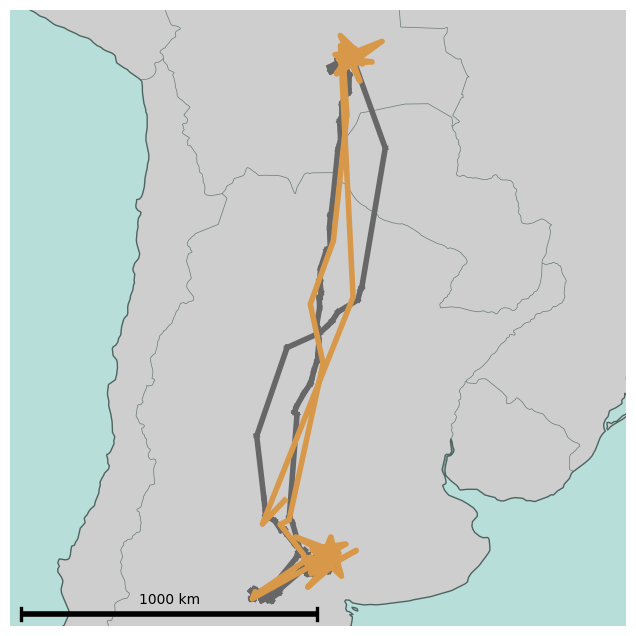

In [ ]:
study_id = "Bildstein_b6a0d056_raw_merged"
test_set = "test_temporal"
indiv_idx = 3


df = pd.read_csv(
    f"../cleaned-v3-filtered/{study_id}.csv",
    parse_dates=["timestamp"],
)

df = df[df.set == test_set]
# individual_id = df["individual-local-identifier"].value_counts().idxmax()
individual_id = df["individual-local-identifier"].unique()[indiv_idx]
print(individual_id)

track = df[df["individual-local-identifier"] == individual_id].sort_values("timestamp")
track = track[track.step_length_m < track.step_length_m.quantile(0.99)]



### PREDS
track_12h = track.iloc[::12].copy()
pred_path = max(
    (
        p
        for p in (paths.repo_root() / "results" / "bench" / "runs").glob(
            f"study={study_id}__ts=12h__cov=all__method=issf_mlp__seed=0__k=*/predictions/{test_set}.pt"
        )
    ),
    key=lambda p: p.stat().st_mtime,
)
pred_payload = torch.load(pred_path, map_location="cpu")
pred_index = {
    int(point_id): i for i, point_id in enumerate(pred_payload["point_id_start"].tolist())
}
to_3857 = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
from_3857 = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)

# start at start point
pred_lon = [track.start_lon.values[0]]
pred_lat = [track.start_lat.values[0]]
g = torch.Generator().manual_seed(2)
h, w = pred_payload["scores"].shape[1:]
for row in track_12h.itertuples(index=False):
    idx = pred_index.get(int(row.point_id_start))
    if idx is None:
        continue
    pix = int(
        torch.multinomial(
            torch.softmax(pred_payload["scores"][idx].reshape(-1), dim=0),
            1,
            generator=g,
        ).item()
    )
    sample_row, sample_col = divmod(pix, w)
    start_x, start_y = to_3857.transform(float(row.start_lon), float(row.start_lat))
    lon, lat = from_3857.transform(
        start_x + (sample_col - (w // 2)) * float(pred_payload["pixel_size_m"]),
        start_y + ((h // 2) - sample_row) * float(pred_payload["pixel_size_m"]),
    )
    pred_lon.append(lon)
    pred_lat.append(lat)

###



fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})
ax.add_feature(cfeature.OCEAN, facecolor=MAP_OCEAN_COLOR)
ax.add_feature(cfeature.LAND, facecolor=MAP_LAND_COLOR)
ax.add_feature(cfeature.COASTLINE, edgecolor=MAP_COASTLINE_COLOR, linewidth=1.0)
ax.add_feature(cfeature.BORDERS, edgecolor=MAP_COASTLINE_COLOR, linewidth=0.5, alpha=0.8)

max_dist_to_connect = 50 * np.quantile(track.step_length_m, 0.9)
last = None
for i, row in track.iterrows():

    if last is not None and haversine(row.start_lat, row.start_lon, last[0], last[1]) < max_dist_to_connect:
        ax.plot([last[1], row.start_lon], 
            [last[0], row.start_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    ax.plot([row.start_lon, row.end_lon], 
            [row.start_lat, row.end_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    last = [row.end_lat, row.end_lon]


if pred_lon:
    ax.plot(pred_lon, pred_lat, 
            "-o", color=MAP_PREDICTED_COLOR, 
            linewidth=4, 
            markersize=2,
            alpha=1.0)


lon = track["start_lon"].to_numpy()
lat = track["start_lat"].to_numpy()
if pred_lon:
    lon = np.r_[lon, pred_lon]
    lat = np.r_[lat, pred_lat]
ax.set_xlim(lon.min() - 1, lon.max() + 1)
ax.set_ylim(lat.min() - 1, lat.max() + 1)
ax.set_box_aspect(1)

# add_scalebar(ax, 
#             length_km=1000,
#             location=(-1.1,0.02))

# ax.set_xlabel("Longitude")
# ax.set_ylabel("Latitude")
# ax.set_title(f"{study_id}\n{individual_id}")

for spine in ax.spines.values():
    spine.set_visible(False)


plt.savefig(f'mini_maps/turkey_vulture_{individual_id.replace(" ", "_")}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'mini_maps/turkey_vulture_{individual_id.replace(" ", "_")}.png', dpi=300, bbox_inches='tight')

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


COGU-IA191651-Langenwerder


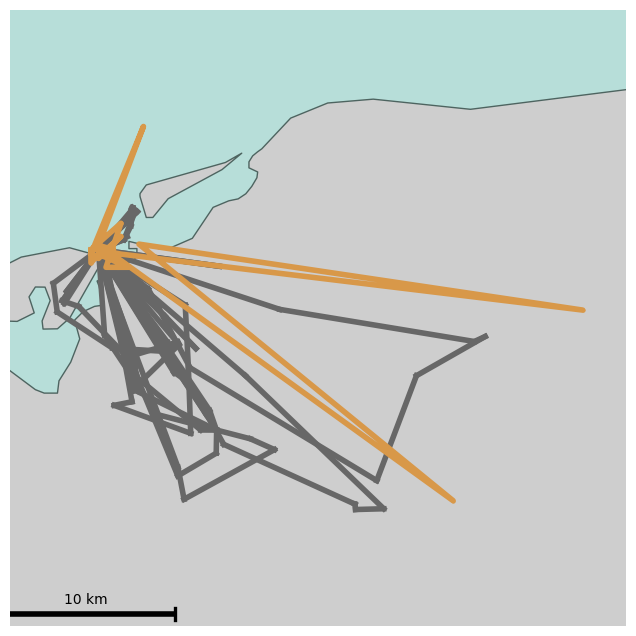

In [ ]:
study_id = "Garthe_ae7b0b8c_raw_merged"
test_set = "test_temporal"
indiv_idx = 3


df = pd.read_csv(
    f"../cleaned-v3-filtered/{study_id}.csv",
    parse_dates=["timestamp"],
)

df = df[df.set == test_set]
# individual_id = df["individual-local-identifier"].value_counts().idxmax()
individual_id = df["individual-local-identifier"].unique()[indiv_idx]
print(individual_id)

track = df[df["individual-local-identifier"] == individual_id].sort_values("timestamp")
track = track[track.step_length_m < track.step_length_m.quantile(0.99)]



### PREDS
track_12h = track.iloc[::12].copy()
pred_path = max(
    (
        p
        for p in (paths.repo_root() / "results" / "bench" / "runs").glob(
            f"study={study_id}__ts=12h__cov=all__method=issf_mlp__seed=0__k=*/predictions/{test_set}.pt"
        )
    ),
    key=lambda p: p.stat().st_mtime,
)
pred_payload = torch.load(pred_path, map_location="cpu")
pred_index = {
    int(point_id): i for i, point_id in enumerate(pred_payload["point_id_start"].tolist())
}
to_3857 = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
from_3857 = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)

# start at start point
pred_lon = [track.start_lon.values[0]]
pred_lat = [track.start_lat.values[0]]
g = torch.Generator().manual_seed(2)
h, w = pred_payload["scores"].shape[1:]
for row in track_12h.itertuples(index=False):
    idx = pred_index.get(int(row.point_id_start))
    if idx is None:
        continue
    pix = int(
        torch.multinomial(
            torch.softmax(pred_payload["scores"][idx].reshape(-1), dim=0),
            1,
            generator=g,
        ).item()
    )
    sample_row, sample_col = divmod(pix, w)
    start_x, start_y = to_3857.transform(float(row.start_lon), float(row.start_lat))
    lon, lat = from_3857.transform(
        start_x + (sample_col - (w // 2)) * float(pred_payload["pixel_size_m"]),
        start_y + ((h // 2) - sample_row) * float(pred_payload["pixel_size_m"]),
    )
    pred_lon.append(lon)
    pred_lat.append(lat)

###



fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})
ax.add_feature(cfeature.OCEAN, facecolor=MAP_OCEAN_COLOR)
ax.add_feature(cfeature.LAND, facecolor=MAP_LAND_COLOR)
ax.add_feature(cfeature.COASTLINE, edgecolor=MAP_COASTLINE_COLOR, linewidth=1.0)
ax.add_feature(cfeature.BORDERS, edgecolor=MAP_COASTLINE_COLOR, linewidth=0.5, alpha=0.8)

max_dist_to_connect = 50 * np.quantile(track.step_length_m, 0.9)
last = None
for i, row in track.iterrows():

    if last is not None and haversine(row.start_lat, row.start_lon, last[0], last[1]) < max_dist_to_connect:
        ax.plot([last[1], row.start_lon], 
            [last[0], row.start_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    ax.plot([row.start_lon, row.end_lon], 
            [row.start_lat, row.end_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    last = [row.end_lat, row.end_lon]


if pred_lon:
    ax.plot(pred_lon, pred_lat, 
            "-o", color=MAP_PREDICTED_COLOR, 
            linewidth=4, 
            markersize=2,
            alpha=1.0)


lon = track["start_lon"].to_numpy()
lat = track["start_lat"].to_numpy()
if pred_lon:
    lon = np.r_[lon, pred_lon]
    lat = np.r_[lat, pred_lat]
ax.set_xlim(lon.min() - 0.1, lon.max() + 0.1)
ax.set_ylim(lat.min() - 0.1, lat.max() + 0.1)
ax.set_box_aspect(1)

# add_scalebar(ax, 
#             length_km=10,
#             location=(0.08,0.02))

# ax.set_xlabel("Longitude")
# ax.set_ylabel("Latitude")
# ax.set_title(f"{study_id}\n{individual_id}")

for spine in ax.spines.values():
    spine.set_visible(False)


plt.savefig(f'mini_maps/mew_gull_{individual_id.replace(" ", "_")}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'mini_maps/mew_gull_{individual_id.replace(" ", "_")}.png', dpi=300, bbox_inches='tight')

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


EE01856


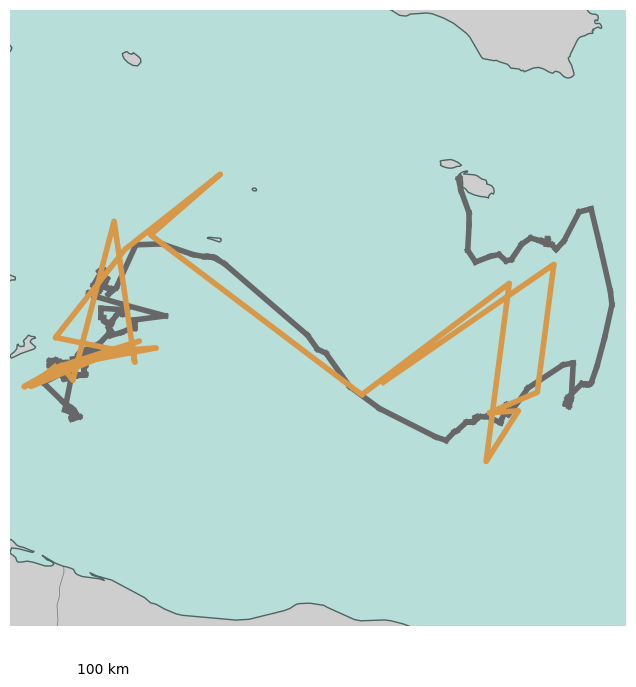

In [ ]:
study_id = "Lago_8b91498b_raw_merged"
test_set = "test_temporal"
indiv_idx = 3


df = pd.read_csv(
    f"../cleaned-v3-filtered/{study_id}.csv",
    parse_dates=["timestamp"],
)

df = df[df.set == test_set]
# individual_id = df["individual-local-identifier"].value_counts().idxmax()
individual_id = df["individual-local-identifier"].unique()[indiv_idx]
print(individual_id)

track = df[df["individual-local-identifier"] == individual_id].sort_values("timestamp")
track = track[track.step_length_m < track.step_length_m.quantile(0.99)]



### PREDS
track_12h = track.iloc[::12].copy()
pred_path = max(
    (
        p
        for p in (paths.repo_root() / "results" / "bench" / "runs").glob(
            f"study={study_id}__ts=12h__cov=all__method=issf_mlp__seed=0__k=*/predictions/{test_set}.pt"
        )
    ),
    key=lambda p: p.stat().st_mtime,
)
pred_payload = torch.load(pred_path, map_location="cpu")
pred_index = {
    int(point_id): i for i, point_id in enumerate(pred_payload["point_id_start"].tolist())
}
to_3857 = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
from_3857 = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)

# start at start point
pred_lon = [track.start_lon.values[0]]
pred_lat = [track.start_lat.values[0]]
g = torch.Generator().manual_seed(2)
h, w = pred_payload["scores"].shape[1:]
for row in track_12h.itertuples(index=False):
    idx = pred_index.get(int(row.point_id_start))
    if idx is None:
        continue
    pix = int(
        torch.multinomial(
            torch.softmax(pred_payload["scores"][idx].reshape(-1), dim=0),
            1,
            generator=g,
        ).item()
    )
    sample_row, sample_col = divmod(pix, w)
    start_x, start_y = to_3857.transform(float(row.start_lon), float(row.start_lat))
    lon, lat = from_3857.transform(
        start_x + (sample_col - (w // 2)) * float(pred_payload["pixel_size_m"]),
        start_y + ((h // 2) - sample_row) * float(pred_payload["pixel_size_m"]),
    )
    pred_lon.append(lon)
    pred_lat.append(lat)

###



fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})
ax.add_feature(cfeature.OCEAN, facecolor=MAP_OCEAN_COLOR)
ax.add_feature(cfeature.LAND, facecolor=MAP_LAND_COLOR)
ax.add_feature(cfeature.COASTLINE, edgecolor=MAP_COASTLINE_COLOR, linewidth=1.0)
ax.add_feature(cfeature.BORDERS, edgecolor=MAP_COASTLINE_COLOR, linewidth=0.5, alpha=0.8)

max_dist_to_connect = 50 * np.quantile(track.step_length_m, 0.9)
last = None
for i, row in track.iterrows():

    if last is not None and haversine(row.start_lat, row.start_lon, last[0], last[1]) < max_dist_to_connect:
        ax.plot([last[1], row.start_lon], 
            [last[0], row.start_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    ax.plot([row.start_lon, row.end_lon], 
            [row.start_lat, row.end_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    last = [row.end_lat, row.end_lon]


if pred_lon:
    ax.plot(pred_lon, pred_lat, 
            "-o", color=MAP_PREDICTED_COLOR, 
            linewidth=4, 
            markersize=2,
            alpha=1.0)


lon = track["start_lon"].to_numpy()
lat = track["start_lat"].to_numpy()
if pred_lon:
    lon = np.r_[lon, pred_lon]
    lat = np.r_[lat, pred_lat]
ax.set_xlim(lon.min() - 0.1, lon.max() + 0.1)
ax.set_ylim(lat.min() - 0.1, lat.max() + 0.1)
ax.set_box_aspect(1)

# add_scalebar(ax, 
#             length_km=100,
#             location=(0.03,-0.65))

# ax.set_xlabel("Longitude")
# ax.set_ylabel("Latitude")
# ax.set_title(f"{study_id}\n{individual_id}")

for spine in ax.spines.values():
    spine.set_visible(False)


plt.savefig(f'mini_maps/shearwater_{individual_id.replace(" ", "_")}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'mini_maps/shearwater_{individual_id.replace(" ", "_")}.png', dpi=300, bbox_inches='tight')

26


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


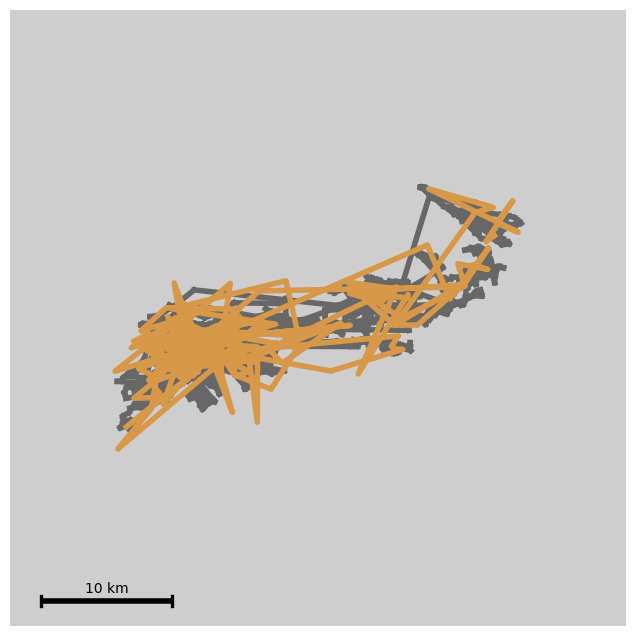

In [ ]:
study_id = "aikens2024_pronghorn"
test_set = "test_temporal"
indiv_idx = 0


df = pd.read_csv(
    f"../cleaned-v3-filtered/{study_id}.csv",
    parse_dates=["timestamp"],
)

df = df[df.set == test_set]
# individual_id = df["individual-local-identifier"].value_counts().idxmax()
individual_id = df["individual-local-identifier"].unique()[indiv_idx]
print(individual_id)

track = df[df["individual-local-identifier"] == individual_id].sort_values("timestamp")
track = track[track.step_length_m < track.step_length_m.quantile(0.99)]



### PREDS
track_12h = track.iloc[::24].copy()
pred_path = max(
    (
        p
        for p in (paths.repo_root() / "results" / "bench" / "runs").glob(
            f"study={study_id}__ts=1d__cov=all__method=issf_mlp__seed=0__k=*/predictions/{test_set}.pt"
        )
    ),
    key=lambda p: p.stat().st_mtime,
)
pred_payload = torch.load(pred_path, map_location="cpu")
pred_index = {
    int(point_id): i for i, point_id in enumerate(pred_payload["point_id_start"].tolist())
}
to_3857 = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
from_3857 = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)

# start at start point
pred_lon = [track.start_lon.values[0]]
pred_lat = [track.start_lat.values[0]]
g = torch.Generator().manual_seed(2)
h, w = pred_payload["scores"].shape[1:]
for row in track_12h.itertuples(index=False):
    idx = pred_index.get(int(row.point_id_start))
    if idx is None:
        continue
    pix = int(
        torch.multinomial(
            torch.softmax(pred_payload["scores"][idx].reshape(-1), dim=0),
            1,
            generator=g,
        ).item()
    )
    sample_row, sample_col = divmod(pix, w)
    start_x, start_y = to_3857.transform(float(row.start_lon), float(row.start_lat))
    lon, lat = from_3857.transform(
        start_x + (sample_col - (w // 2)) * float(pred_payload["pixel_size_m"]),
        start_y + ((h // 2) - sample_row) * float(pred_payload["pixel_size_m"]),
    )
    pred_lon.append(lon)
    pred_lat.append(lat)

###



fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})
ax.add_feature(cfeature.OCEAN, facecolor=MAP_OCEAN_COLOR)
ax.add_feature(cfeature.LAND, facecolor=MAP_LAND_COLOR)
ax.add_feature(cfeature.COASTLINE, edgecolor=MAP_COASTLINE_COLOR, linewidth=1.0)
ax.add_feature(cfeature.BORDERS, edgecolor=MAP_COASTLINE_COLOR, linewidth=0.5, alpha=0.8)
ax.add_feature(cfeature.LAKES, facecolor=MAP_RIVERS_LAKES_COLOR, edgecolor=MAP_RIVERS_LAKES_COLOR, linewidth=0.1)
ax.add_feature(cfeature.RIVERS, edgecolor=MAP_RIVERS_LAKES_COLOR, linewidth=0.1)

max_dist_to_connect = 50 * np.quantile(track.step_length_m, 0.9)
last = None
for i, row in track.iterrows():

    if last is not None and haversine(row.start_lat, row.start_lon, last[0], last[1]) < max_dist_to_connect:
        ax.plot([last[1], row.start_lon], 
            [last[0], row.start_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    ax.plot([row.start_lon, row.end_lon], 
            [row.start_lat, row.end_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    last = [row.end_lat, row.end_lon]


if pred_lon:
    ax.plot(pred_lon, pred_lat, 
            "-o", color=MAP_PREDICTED_COLOR, 
            linewidth=4, 
            markersize=2,
            alpha=1.0)


lon = track["start_lon"].to_numpy()
lat = track["start_lat"].to_numpy()
if pred_lon:
    lon = np.r_[lon, pred_lon]
    lat = np.r_[lat, pred_lat]
ax.set_xlim(lon.min() - 0.1, lon.max() + 0.1)
ax.set_ylim(lat.min() - 0.1, lat.max() + 0.1)
ax.set_box_aspect(1)

# add_scalebar(ax, 
#             length_km=10,
#             location=(0.05,-0.1))

# ax.set_xlabel("Longitude")
# ax.set_ylabel("Latitude")
# ax.set_title(f"{study_id}\n{individual_id}")

for spine in ax.spines.values():
    spine.set_visible(False)


plt.savefig(f'mini_maps/pronghorn_{str(individual_id).replace(" ", "_")}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'mini_maps/pronghorn_{str(individual_id).replace(" ", "_")}.png', dpi=300, bbox_inches='tight')

Z6402


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


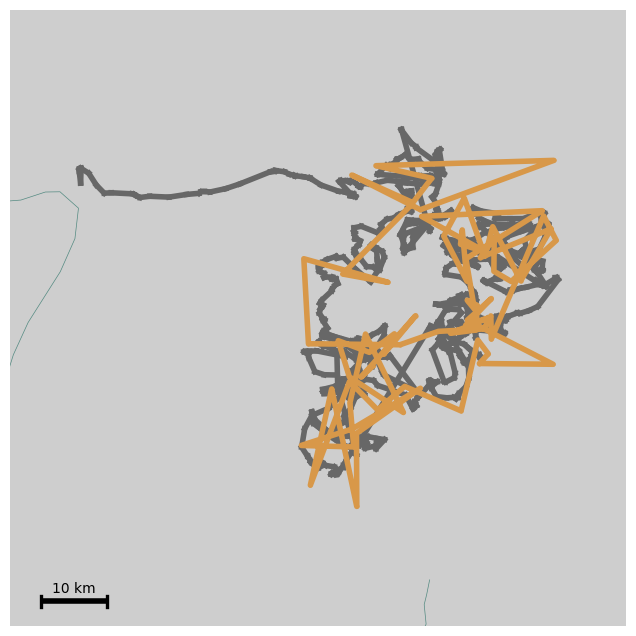

In [ ]:
study_id = "BartlamBrooks_c9b4f9b5_raw_merged"
test_set = "test_temporal"
indiv_idx = 2


df = pd.read_csv(
    f"../cleaned-v3-filtered/{study_id}.csv",
    parse_dates=["timestamp"],
)

df = df[df.set == test_set]
# individual_id = df["individual-local-identifier"].value_counts().idxmax()
individual_id = df["individual-local-identifier"].unique()[indiv_idx]
print(individual_id)

track = df[df["individual-local-identifier"] == individual_id].sort_values("timestamp")
track = track[track.step_length_m < track.step_length_m.quantile(0.99)]



### PREDS
track_12h = track.iloc[::12].copy()
pred_path = max(
    (
        p
        for p in (paths.repo_root() / "results" / "bench" / "runs").glob(
            f"study={study_id}__ts=12h__cov=all__method=issf_mlp__seed=0__k=*/predictions/{test_set}.pt"
        )
    ),
    key=lambda p: p.stat().st_mtime,
)
pred_payload = torch.load(pred_path, map_location="cpu")
pred_index = {
    int(point_id): i for i, point_id in enumerate(pred_payload["point_id_start"].tolist())
}
to_3857 = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
from_3857 = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)

# start at start point
pred_lon = [track.start_lon.values[0]]
pred_lat = [track.start_lat.values[0]]
g = torch.Generator().manual_seed(2)
h, w = pred_payload["scores"].shape[1:]
for row in track_12h.itertuples(index=False):
    idx = pred_index.get(int(row.point_id_start))
    if idx is None:
        continue
    pix = int(
        torch.multinomial(
            torch.softmax(pred_payload["scores"][idx].reshape(-1), dim=0),
            1,
            generator=g,
        ).item()
    )
    sample_row, sample_col = divmod(pix, w)
    start_x, start_y = to_3857.transform(float(row.start_lon), float(row.start_lat))
    lon, lat = from_3857.transform(
        start_x + (sample_col - (w // 2)) * float(pred_payload["pixel_size_m"]),
        start_y + ((h // 2) - sample_row) * float(pred_payload["pixel_size_m"]),
    )
    pred_lon.append(lon)
    pred_lat.append(lat)

###



fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})
ax.add_feature(cfeature.OCEAN, facecolor=MAP_OCEAN_COLOR)
ax.add_feature(cfeature.LAND, facecolor=MAP_LAND_COLOR)
ax.add_feature(cfeature.COASTLINE, edgecolor=MAP_COASTLINE_COLOR, linewidth=1.0)
ax.add_feature(cfeature.BORDERS, edgecolor=MAP_COASTLINE_COLOR, linewidth=0.5, alpha=0.8)
ax.add_feature(cfeature.LAKES, facecolor=MAP_RIVERS_LAKES_COLOR, edgecolor=MAP_RIVERS_LAKES_COLOR, linewidth=0.5)
ax.add_feature(cfeature.RIVERS, edgecolor=MAP_RIVERS_LAKES_COLOR, linewidth=0.5)

max_dist_to_connect = 50 * np.quantile(track.step_length_m, 0.9)
last = None
for i, row in track.iterrows():

    if last is not None and haversine(row.start_lat, row.start_lon, last[0], last[1]) < max_dist_to_connect:
        ax.plot([last[1], row.start_lon], 
            [last[0], row.start_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    ax.plot([row.start_lon, row.end_lon], 
            [row.start_lat, row.end_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    last = [row.end_lat, row.end_lon]


if pred_lon:
    ax.plot(pred_lon, pred_lat, 
            "-o", color=MAP_PREDICTED_COLOR, 
            linewidth=4, 
            markersize=2,
            alpha=1.0)


lon = track["start_lon"].to_numpy()
lat = track["start_lat"].to_numpy()
if pred_lon:
    lon = np.r_[lon, pred_lon]
    lat = np.r_[lat, pred_lat]
ax.set_xlim(lon.min() - 0.1, lon.max() + 0.1)
ax.set_ylim(lat.min() - 0.1, lat.max() + 0.1)
ax.set_box_aspect(1)

# add_scalebar(ax, 
#             length_km=10,
#             location=(0.05,-0.05))

# ax.set_xlabel("Longitude")
# ax.set_ylabel("Latitude")
# ax.set_title(f"{study_id}\n{individual_id}")

for spine in ax.spines.values():
    spine.set_visible(False)


plt.savefig(f'mini_maps/zebra_{individual_id.replace(" ", "_")}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'mini_maps/zebra_{individual_id.replace(" ", "_")}.png', dpi=300, bbox_inches='tight')

2018


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


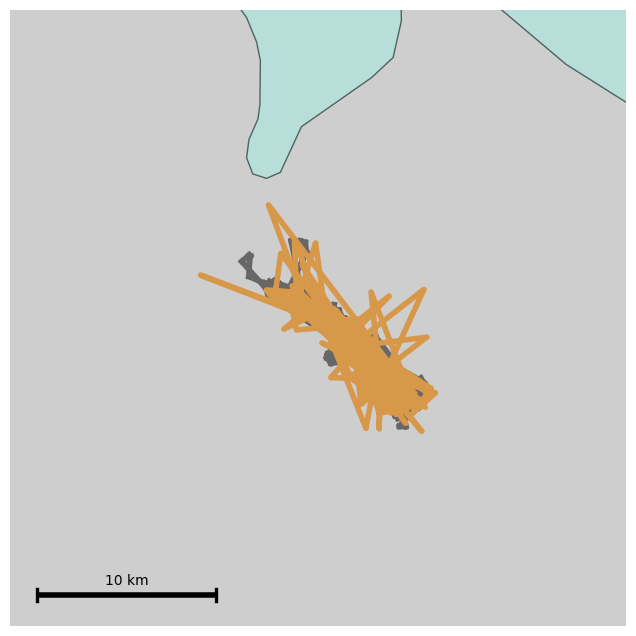

In [ ]:
study_id = "forrest2024_buffalo"
test_set = "test_temporal"
indiv_idx = 1


df = pd.read_csv(
    f"../cleaned-v3-filtered/{study_id}.csv",
    parse_dates=["timestamp"],
)

df = df[df.set == test_set]
# individual_id = df["individual-local-identifier"].value_counts().idxmax()
individual_id = df["individual-local-identifier"].unique()[indiv_idx]
print(individual_id)

track = df[df["individual-local-identifier"] == individual_id].sort_values("timestamp")
track = track[track.step_length_m < track.step_length_m.quantile(0.99)]



### PREDS
track_12h = track.iloc[::12].copy()
pred_path = max(
    (
        p
        for p in (paths.repo_root() / "results" / "bench" / "runs").glob(
            f"study={study_id}__ts=12h__cov=all__method=issf_mlp__seed=0__k=*/predictions/{test_set}.pt"
        )
    ),
    key=lambda p: p.stat().st_mtime,
)
pred_payload = torch.load(pred_path, map_location="cpu")
pred_index = {
    int(point_id): i for i, point_id in enumerate(pred_payload["point_id_start"].tolist())
}
to_3857 = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
from_3857 = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)

# start at start point
pred_lon = [track.start_lon.values[0]]
pred_lat = [track.start_lat.values[0]]
g = torch.Generator().manual_seed(2)
h, w = pred_payload["scores"].shape[1:]
for row in track_12h.itertuples(index=False):
    idx = pred_index.get(int(row.point_id_start))
    if idx is None:
        continue
    pix = int(
        torch.multinomial(
            torch.softmax(pred_payload["scores"][idx].reshape(-1), dim=0),
            1,
            generator=g,
        ).item()
    )
    sample_row, sample_col = divmod(pix, w)
    start_x, start_y = to_3857.transform(float(row.start_lon), float(row.start_lat))
    lon, lat = from_3857.transform(
        start_x + (sample_col - (w // 2)) * float(pred_payload["pixel_size_m"]),
        start_y + ((h // 2) - sample_row) * float(pred_payload["pixel_size_m"]),
    )
    pred_lon.append(lon)
    pred_lat.append(lat)

###



fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})
ax.add_feature(cfeature.OCEAN, facecolor=MAP_OCEAN_COLOR)
ax.add_feature(cfeature.LAND, facecolor=MAP_LAND_COLOR)
ax.add_feature(cfeature.COASTLINE, edgecolor=MAP_COASTLINE_COLOR, linewidth=1.0)
ax.add_feature(cfeature.BORDERS, edgecolor=MAP_COASTLINE_COLOR, linewidth=0.5, alpha=0.8)
ax.add_feature(cfeature.LAKES, facecolor=MAP_RIVERS_LAKES_COLOR, edgecolor=MAP_RIVERS_LAKES_COLOR, linewidth=0.5)
ax.add_feature(cfeature.RIVERS, edgecolor=MAP_RIVERS_LAKES_COLOR, linewidth=0.5)

max_dist_to_connect = 50 * np.quantile(track.step_length_m, 0.9)
last = None
for i, row in track.iterrows():

    if last is not None and haversine(row.start_lat, row.start_lon, last[0], last[1]) < max_dist_to_connect:
        ax.plot([last[1], row.start_lon], 
            [last[0], row.start_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    ax.plot([row.start_lon, row.end_lon], 
            [row.start_lat, row.end_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    last = [row.end_lat, row.end_lon]


if pred_lon:
    ax.plot(pred_lon, pred_lat, 
            "-o", color=MAP_PREDICTED_COLOR, 
            linewidth=4, 
            markersize=2,
            alpha=1.0)


lon = track["start_lon"].to_numpy()
lat = track["start_lat"].to_numpy()
if pred_lon:
    lon = np.r_[lon, pred_lon]
    lat = np.r_[lat, pred_lat]
ax.set_xlim(lon.min() - 0.1, lon.max() + 0.1)
ax.set_ylim(lat.min() - 0.1, lat.max() + 0.1)
ax.set_box_aspect(1)

# add_scalebar(ax, 
#             length_km=10,
#             location=(0.05,0.05))

# ax.set_xlabel("Longitude")
# ax.set_ylabel("Latitude")
# ax.set_title(f"{study_id}\n{individual_id}")

for spine in ax.spines.values():
    spine.set_visible(False)


plt.savefig(f'mini_maps/buffalo_{str(individual_id).replace(" ", "_")}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'mini_maps/buffalo_{str(individual_id).replace(" ", "_")}.png', dpi=300, bbox_inches='tight')

CM15


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


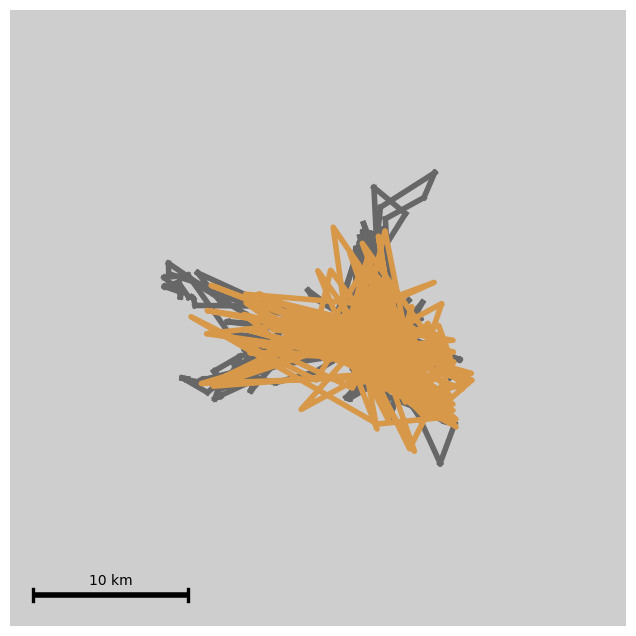

In [ ]:
study_id = "Bellan_48c93576_raw_merged"
test_set = "test_individual"
indiv_idx = 0


df = pd.read_csv(
    f"../cleaned-v3-filtered/{study_id}.csv",
    parse_dates=["timestamp"],
)

df = df[df.set == test_set]
# individual_id = df["individual-local-identifier"].value_counts().idxmax()
individual_id = df["individual-local-identifier"].unique()[indiv_idx]
print(individual_id)

track = df[df["individual-local-identifier"] == individual_id].sort_values("timestamp")
track = track[track.step_length_m < track.step_length_m.quantile(0.99)]



### PREDS
track_12h = track.iloc[::12].copy()
pred_path = max(
    (
        p
        for p in (paths.repo_root() / "results" / "bench" / "runs").glob(
            f"study={study_id}__ts=12h__cov=all__method=issf_mlp__seed=0__k=*/predictions/{test_set}.pt"
        )
    ),
    key=lambda p: p.stat().st_mtime,
)
pred_payload = torch.load(pred_path, map_location="cpu")
pred_index = {
    int(point_id): i for i, point_id in enumerate(pred_payload["point_id_start"].tolist())
}
to_3857 = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
from_3857 = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)

# start at start point
pred_lon = [track.start_lon.values[0]]
pred_lat = [track.start_lat.values[0]]
g = torch.Generator().manual_seed(2)
h, w = pred_payload["scores"].shape[1:]
for row in track_12h.itertuples(index=False):
    idx = pred_index.get(int(row.point_id_start))
    if idx is None:
        continue
    pix = int(
        torch.multinomial(
            torch.softmax(pred_payload["scores"][idx].reshape(-1), dim=0),
            1,
            generator=g,
        ).item()
    )
    sample_row, sample_col = divmod(pix, w)
    start_x, start_y = to_3857.transform(float(row.start_lon), float(row.start_lat))
    lon, lat = from_3857.transform(
        start_x + (sample_col - (w // 2)) * float(pred_payload["pixel_size_m"]),
        start_y + ((h // 2) - sample_row) * float(pred_payload["pixel_size_m"]),
    )
    pred_lon.append(lon)
    pred_lat.append(lat)

###



fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})
ax.add_feature(cfeature.OCEAN, facecolor=MAP_OCEAN_COLOR)
ax.add_feature(cfeature.LAND, facecolor=MAP_LAND_COLOR)
ax.add_feature(cfeature.COASTLINE, edgecolor=MAP_COASTLINE_COLOR, linewidth=1.0)
ax.add_feature(cfeature.BORDERS, edgecolor=MAP_COASTLINE_COLOR, linewidth=0.5, alpha=0.8)
ax.add_feature(cfeature.LAKES, facecolor=MAP_RIVERS_LAKES_COLOR, edgecolor=MAP_RIVERS_LAKES_COLOR, linewidth=0.5)
ax.add_feature(cfeature.RIVERS, edgecolor=MAP_RIVERS_LAKES_COLOR, linewidth=0.5)

max_dist_to_connect = 50 * np.quantile(track.step_length_m, 0.9)
last = None
for i, row in track.iterrows():

    if last is not None and haversine(row.start_lat, row.start_lon, last[0], last[1]) < max_dist_to_connect:
        ax.plot([last[1], row.start_lon], 
            [last[0], row.start_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    ax.plot([row.start_lon, row.end_lon], 
            [row.start_lat, row.end_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    last = [row.end_lat, row.end_lon]


if pred_lon:
    ax.plot(pred_lon, pred_lat, 
            "-o", color=MAP_PREDICTED_COLOR, 
            linewidth=4, 
            markersize=2,
            alpha=1.0)


lon = track["start_lon"].to_numpy()
lat = track["start_lat"].to_numpy()
if pred_lon:
    lon = np.r_[lon, pred_lon]
    lat = np.r_[lat, pred_lat]
ax.set_xlim(lon.min() - 0.1, lon.max() + 0.1)
ax.set_ylim(lat.min() - 0.1, lat.max() + 0.1)
ax.set_box_aspect(1)

# add_scalebar(ax, 
#             length_km=10,
#             location=(0.05,0.05))

# ax.set_xlabel("Longitude")
# ax.set_ylabel("Latitude")
# ax.set_title(f"{study_id}\n{individual_id}")

for spine in ax.spines.values():
    spine.set_visible(False)


plt.savefig(f'mini_maps/jackal_{individual_id.replace(" ", "_")}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'mini_maps/jackal_{individual_id.replace(" ", "_")}.png', dpi=300, bbox_inches='tight')

6012


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


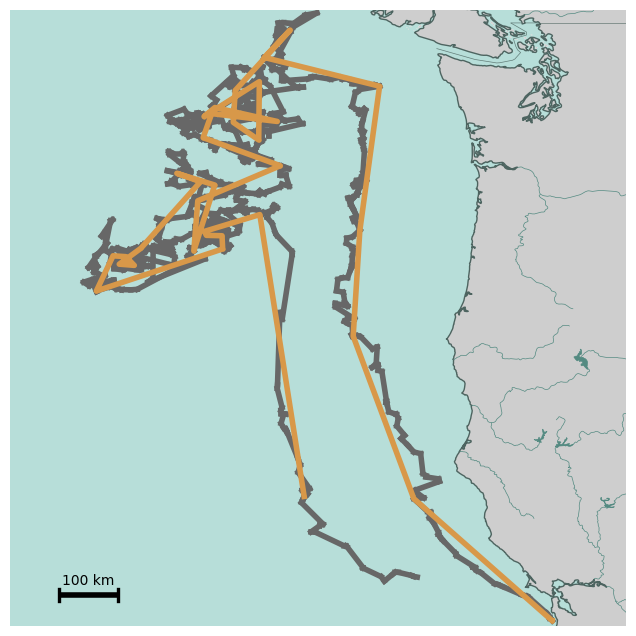

In [ ]:
study_id = "costa2024_elephant_seals"
test_set = "test_individual"
indiv_idx = 0


df = pd.read_csv(
    f"../cleaned-v3-filtered/{study_id}.csv",
    parse_dates=["timestamp"],
)

df = df[df.set == test_set]
# individual_id = df["individual-local-identifier"].value_counts().idxmax()
individual_id = df["individual-local-identifier"].unique()[indiv_idx]
print(individual_id)

track = df[df["individual-local-identifier"] == individual_id].sort_values("timestamp")
track = track[track.step_length_m < track.step_length_m.quantile(0.99)]



### PREDS
track_12h = track.iloc[::24].copy()
pred_path = max(
    (
        p
        for p in (paths.repo_root() / "results" / "bench" / "runs").glob(
            f"study={study_id}__ts=1d__cov=all__method=issf_mlp__seed=0__k=*/predictions/{test_set}.pt"
        )
    ),
    key=lambda p: p.stat().st_mtime,
)
pred_payload = torch.load(pred_path, map_location="cpu")
pred_index = {
    int(point_id): i for i, point_id in enumerate(pred_payload["point_id_start"].tolist())
}
to_3857 = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
from_3857 = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)


# start at start point
pred_lon = [track.start_lon.values[0]]
pred_lat = [track.start_lat.values[0]]
g = torch.Generator().manual_seed(4)
h, w = pred_payload["scores"].shape[1:]
for row in track_12h.itertuples(index=False):
    idx = pred_index.get(int(row.point_id_start))
    if idx is None:
        continue
    pix = int(
        torch.multinomial(
            torch.softmax(pred_payload["scores"][idx].reshape(-1), dim=0),
            1,
            generator=g,
        ).item()
    )
    sample_row, sample_col = divmod(pix, w)
    start_x, start_y = to_3857.transform(float(row.start_lon), float(row.start_lat))
    lon, lat = from_3857.transform(
        start_x + (sample_col - (w // 2)) * float(pred_payload["pixel_size_m"]),
        start_y + ((h // 2) - sample_row) * float(pred_payload["pixel_size_m"]),
    )
    pred_lon.append(lon)
    pred_lat.append(lat)

###



fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})
ax.add_feature(cfeature.OCEAN, facecolor=MAP_OCEAN_COLOR)
ax.add_feature(cfeature.LAND, facecolor=MAP_LAND_COLOR)
ax.add_feature(cfeature.COASTLINE, edgecolor=MAP_COASTLINE_COLOR, linewidth=1.0)
ax.add_feature(cfeature.BORDERS, edgecolor=MAP_COASTLINE_COLOR, linewidth=0.5, alpha=0.8)
ax.add_feature(cfeature.LAKES, facecolor=MAP_RIVERS_LAKES_COLOR, edgecolor=MAP_RIVERS_LAKES_COLOR, linewidth=0.5)
ax.add_feature(cfeature.RIVERS, edgecolor=MAP_RIVERS_LAKES_COLOR, linewidth=0.5)

max_dist_to_connect = 50 * np.quantile(track.step_length_m, 0.9)
last = None
for i, row in track.iterrows():

    if last is not None and haversine(row.start_lat, row.start_lon, last[0], last[1]) < max_dist_to_connect:
        ax.plot([last[1], row.start_lon], 
            [last[0], row.start_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    ax.plot([row.start_lon, row.end_lon], 
            [row.start_lat, row.end_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    last = [row.end_lat, row.end_lon]


if pred_lon:
    ax.plot(pred_lon, pred_lat, 
            "-o", color=MAP_PREDICTED_COLOR, 
            linewidth=4, 
            markersize=2,
            alpha=1.0)


lon = track["start_lon"].to_numpy()
lat = track["start_lat"].to_numpy()
if pred_lon:
    lon = np.r_[lon, pred_lon]
    lat = np.r_[lat, pred_lat]
ax.set_xlim(lon.min() - 0.1, lon.max() + 0.1)
ax.set_ylim(lat.min() - 0.1, lat.max() + 0.1)
ax.set_box_aspect(1)

# add_scalebar(ax, 
#             length_km=100,
#             location=(-0.04,0.05))

# ax.set_xlabel("Longitude")
# ax.set_ylabel("Latitude")
# ax.set_title(f"{study_id}\n{individual_id}")

for spine in ax.spines.values():
    spine.set_visible(False)


plt.savefig(f'mini_maps/elephant_seal_{str(individual_id).replace(" ", "_")}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'mini_maps/elephant_seal_{str(individual_id).replace(" ", "_")}.png', dpi=300, bbox_inches='tight')

Tanya


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


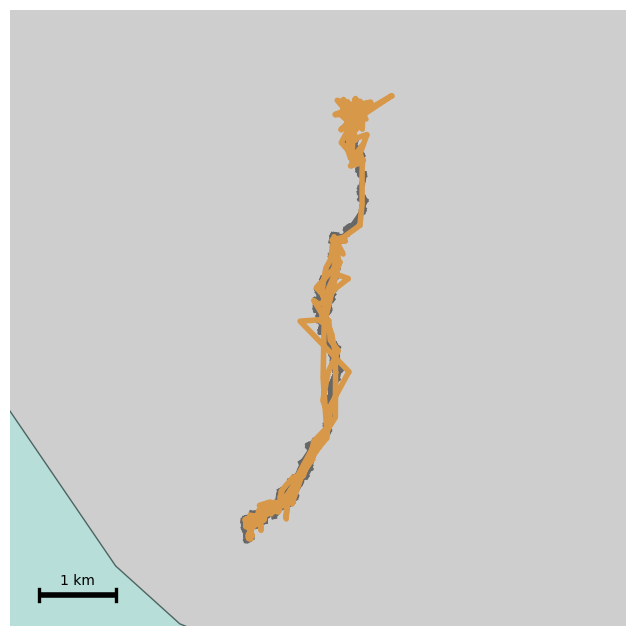

In [ ]:
study_id = "BastilleRousseau_9eaf99f2_raw_merged_Chelonoidis_porteri"
test_set = "test_temporal"
indiv_idx = 2


df = pd.read_csv(
    f"../cleaned-v3-filtered/{study_id}.csv",
    parse_dates=["timestamp"],
)

df = df[df.set == test_set]
# individual_id = df["individual-local-identifier"].value_counts().idxmax()
individual_id = df["individual-local-identifier"].unique()[indiv_idx]
print(individual_id)

track = df[df["individual-local-identifier"] == individual_id].sort_values("timestamp")
track = track[track.step_length_m < track.step_length_m.quantile(0.99)]



### PREDS
track_12h = track.iloc[::24].copy()
pred_path = max(
    (
        p
        for p in (paths.repo_root() / "results" / "bench" / "runs").glob(
            f"study={study_id}__ts=1d__cov=all__method=issf_mlp__seed=0__k=*/predictions/{test_set}.pt"
        )
    ),
    key=lambda p: p.stat().st_mtime,
)
pred_payload = torch.load(pred_path, map_location="cpu")
pred_index = {
    int(point_id): i for i, point_id in enumerate(pred_payload["point_id_start"].tolist())
}
to_3857 = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
from_3857 = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)


# start at start point
pred_lon = [track.start_lon.values[0]]
pred_lat = [track.start_lat.values[0]]
g = torch.Generator().manual_seed(4)
h, w = pred_payload["scores"].shape[1:]
for row in track_12h.itertuples(index=False):
    idx = pred_index.get(int(row.point_id_start))
    if idx is None:
        continue
    pix = int(
        torch.multinomial(
            torch.softmax(pred_payload["scores"][idx].reshape(-1), dim=0),
            1,
            generator=g,
        ).item()
    )
    sample_row, sample_col = divmod(pix, w)
    start_x, start_y = to_3857.transform(float(row.start_lon), float(row.start_lat))
    lon, lat = from_3857.transform(
        start_x + (sample_col - (w // 2)) * float(pred_payload["pixel_size_m"]),
        start_y + ((h // 2) - sample_row) * float(pred_payload["pixel_size_m"]),
    )
    pred_lon.append(lon)
    pred_lat.append(lat)

###



fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": ccrs.PlateCarree()})
ax.add_feature(cfeature.OCEAN, facecolor=MAP_OCEAN_COLOR)
ax.add_feature(cfeature.LAND, facecolor=MAP_LAND_COLOR)
ax.add_feature(cfeature.COASTLINE, edgecolor=MAP_COASTLINE_COLOR, linewidth=1.0)
ax.add_feature(cfeature.BORDERS, edgecolor=MAP_COASTLINE_COLOR, linewidth=0.5, alpha=0.8)
ax.add_feature(cfeature.LAKES, facecolor=MAP_RIVERS_LAKES_COLOR, edgecolor=MAP_RIVERS_LAKES_COLOR, linewidth=0.5)
ax.add_feature(cfeature.RIVERS, edgecolor=MAP_RIVERS_LAKES_COLOR, linewidth=0.5)

max_dist_to_connect = 50 * np.quantile(track.step_length_m, 0.9)
last = None
for i, row in track.iterrows():

    if last is not None and haversine(row.start_lat, row.start_lon, last[0], last[1]) < max_dist_to_connect:
        ax.plot([last[1], row.start_lon], 
            [last[0], row.start_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    ax.plot([row.start_lon, row.end_lon], 
            [row.start_lat, row.end_lat],
            "-o", color=MAP_OBSERVED_COLOR, linewidth=4, markersize=1)

    last = [row.end_lat, row.end_lon]


if pred_lon:
    ax.plot(pred_lon, pred_lat, 
            "-o", color=MAP_PREDICTED_COLOR, 
            linewidth=4, 
            markersize=2,
            alpha=1.0)


lon = track["start_lon"].to_numpy()
lat = track["start_lat"].to_numpy()
if pred_lon:
    lon = np.r_[lon, pred_lon]
    lat = np.r_[lat, pred_lat]
ax.set_xlim(lon.min() - 0.01, lon.max() + 0.01)
ax.set_ylim(lat.min() - 0.01, lat.max() + 0.01)
ax.set_box_aspect(1)

# add_scalebar(ax, 
#             length_km=1,
#             location=(-0.375,0.05))

# ax.set_xlabel("Longitude")
# ax.set_ylabel("Latitude")
# ax.set_title(f"{study_id}\n{individual_id}")

for spine in ax.spines.values():
    spine.set_visible(False)


plt.savefig(f'mini_maps/giant_tortoise_{str(individual_id).replace(" ", "_")}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'mini_maps/giant_tortoise_{str(individual_id).replace(" ", "_")}.png', dpi=300, bbox_inches='tight')